# 02｜EEG 频段功率特征提取

读取 Project 01 保存的滤波后 EEG 数据，计算 Delta、Theta、Alpha、Beta、Gamma 五个频段的通道平均 PSD，并导出 CSV 与热图。

**方法说明**
- 本项目使用频段内平均 PSD（V²/Hz），不是对频段 PSD 积分得到的总功率。
- 相对功率是在本项目选定的五个频段内归一化。
- 本 Notebook 应放在 `Project_02_EEG_BandPower_Features/notebooks/` 中运行。


In [1]:
from pathlib import Path
import json
import mne
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# 自动定位 Project 02 根目录
expected_name = "Project_02_EEG_BandPower_Features"
cwd = Path.cwd().resolve()
candidates = [cwd, *cwd.parents]
PROJECT_DIR = next((p for p in candidates if p.name == expected_name), None)

if PROJECT_DIR is None:
    raise FileNotFoundError(
        f"没有找到项目目录 {expected_name}。"
        "请将 Notebook 放在该项目的 notebooks 文件夹中运行。"
    )

# Project 02 从同级的 Project 01 读取滤波数据
PORTFOLIO_DIR = PROJECT_DIR.parent
PROJECT01_DIR = PORTFOLIO_DIR / "Project_01_EEG_Preprocessing_PSD"
INPUT_FILE = PROJECT01_DIR / "results" / "EEG_filtered_raw.fif"

RESULTS_DIR = PROJECT_DIR / "results"
FIGURES_DIR = PROJECT_DIR / "figures"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

if not INPUT_FILE.exists():
    raise FileNotFoundError(
        f"找不到 Project 01 的输出文件：{INPUT_FILE}\n"
        "请先运行 Project 01，并确认它已生成 results/EEG_filtered_raw.fif。"
    )

print("Project 02目录：", PROJECT_DIR)
print("输入数据：", INPUT_FILE)

raw_filtered = mne.io.read_raw_fif(
    str(INPUT_FILE),
    preload=True,
    verbose=False
)

spectrum = raw_filtered.compute_psd(
    fmin=1, fmax=40, n_fft=256, verbose=False
)
psds, freqs = spectrum.get_data(return_freqs=True)

print("PSD形状：", psds.shape)
print("频率点数量：", len(freqs))


Project 02目录： C:\Users\Administrator\EEG-Analysis-Portfolio\Project_02_EEG_BandPower_Features
输入数据： C:\Users\Administrator\EEG-Analysis-Portfolio\Project_01_EEG_Preprocessing_PSD\results\EEG_filtered_raw.fif
PSD形状： (64, 63)
频率点数量： 63


In [2]:
# 定义五个 EEG 频段
bands = {
    "Delta": (1, 4),
    "Theta": (4, 8),
    "Alpha": (8, 13),
    "Beta":  (13, 30),
    "Gamma": (30, 40),
}

band_power = {}

# 逐个计算频段平均 PSD
for band, (fmin, fmax) in bands.items():

    mask = (freqs >= fmin) & (freqs < fmax)

    # 检查是否选中了频率点
    if not mask.any():
        raise ValueError(f"{band} 频段没有匹配的频率点")

    band_power[band] = psds[:, mask].mean(axis=1)

# 转换为 DataFrame
band_power_df = pd.DataFrame(
    band_power,
    index=raw_filtered.ch_names
)

band_power_df.index.name = "Channel"

print("频段功率矩阵形状：", band_power_df.shape)
print(band_power_df.head())

频段功率矩阵形状： (64, 5)
                Delta         Theta         Alpha          Beta         Gamma
Channel                                                                      
Fc5.     3.151322e-10  6.154480e-11  3.521859e-11  1.076910e-11  2.518365e-12
Fc3.     3.556852e-10  7.088638e-11  4.634995e-11  1.261762e-11  2.543336e-12
Fc1.     3.882326e-10  7.869573e-11  4.562247e-11  1.287488e-11  2.701549e-12
Fcz.     3.967286e-10  8.341724e-11  4.535821e-11  1.308096e-11  2.798858e-12
Fc2.     3.834271e-10  7.467524e-11  4.436449e-11  1.222831e-11  2.492944e-12


In [3]:
# 计算四个频段及 Gamma 的总功率
total_power = band_power_df.sum(axis=1)

# 计算各频段相对功率
relative_power_df = band_power_df.div(
    total_power,
    axis=0
)

print("相对功率矩阵形状：", relative_power_df.shape)

print(relative_power_df.head())

# 检查每个通道的相对功率之和
print("\n每个通道相对功率之和：")
print(relative_power_df.sum(axis=1).head())

相对功率矩阵形状： (64, 5)
            Delta     Theta     Alpha      Beta     Gamma
Channel                                                  
Fc5.     0.741168  0.144749  0.082832  0.025328  0.005923
Fc3.     0.728740  0.145234  0.094963  0.025851  0.005211
Fc1.     0.735112  0.149009  0.086385  0.024378  0.005115
Fcz.     0.732805  0.154082  0.083782  0.024162  0.005170
Fc2.     0.741369  0.144387  0.085780  0.023644  0.004820

每个通道相对功率之和：
Channel
Fc5.    1.0
Fc3.    1.0
Fc1.    1.0
Fcz.    1.0
Fc2.    1.0
dtype: float64


In [4]:
# 保存绝对 PSD 均值与相对功率
absolute_path = RESULTS_DIR / "band_power_absolute.csv"
relative_path = RESULTS_DIR / "band_power_relative.csv"

band_power_df.to_csv(absolute_path)
relative_power_df.to_csv(relative_path)

print("绝对功率已保存：", absolute_path)
print("相对功率已保存：", relative_path)


绝对功率已保存： C:\Users\Administrator\EEG-Analysis-Portfolio\Project_02_EEG_BandPower_Features\results\band_power_absolute.csv
相对功率已保存： C:\Users\Administrator\EEG-Analysis-Portfolio\Project_02_EEG_BandPower_Features\results\band_power_relative.csv


In [5]:
# 重新读取 CSV，检查导出结果
absolute_check = pd.read_csv(
    RESULTS_DIR / "band_power_absolute.csv",
    index_col="Channel"
)

relative_check = pd.read_csv(
    RESULTS_DIR / "band_power_relative.csv",
    index_col="Channel"
)

print("绝对功率形状：", absolute_check.shape)
print("相对功率形状：", relative_check.shape)

print("相对功率总和：")
print(relative_check.sum(axis=1).head())


绝对功率形状： (64, 5)
相对功率形状： (64, 5)
相对功率总和：
Channel
Fc5.    1.0
Fc3.    1.0
Fc1.    1.0
Fcz.    1.0
Fc2.    1.0
dtype: float64


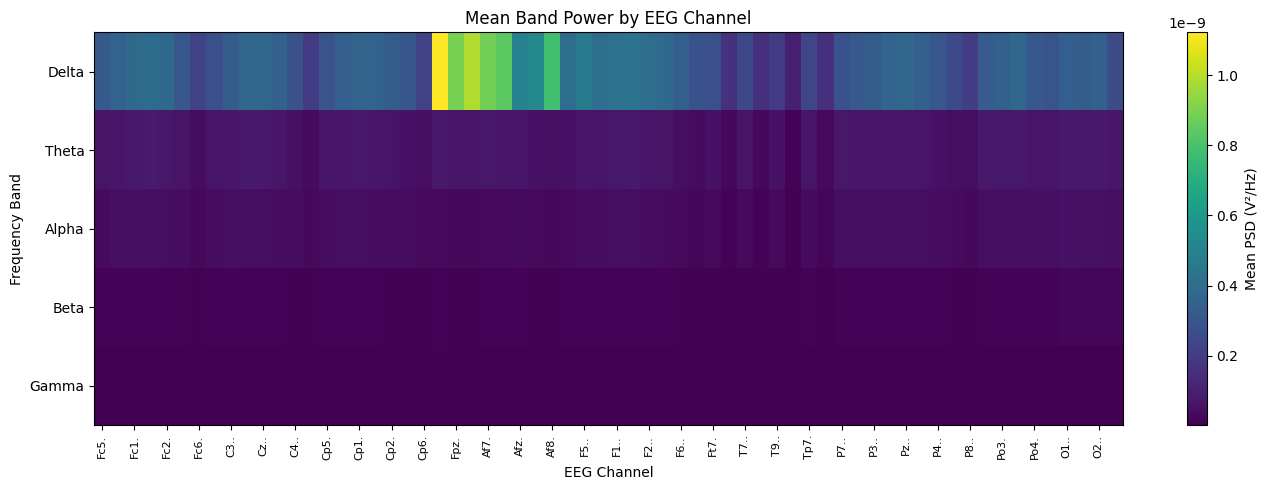

已保存： C:\Users\Administrator\EEG-Analysis-Portfolio\Project_02_EEG_BandPower_Features\figures\band_power_heatmap.png


In [6]:


plt.figure(figsize=(14, 5))

plt.imshow(
    band_power_df.T,
    aspect="auto",
    interpolation="nearest",
    cmap="viridis"
)

plt.yticks(
    range(len(band_power_df.columns)),
    band_power_df.columns
)

# 横轴标签优化：每隔两个通道显示一个
ax = plt.gca()
ax.set_xticks(range(0, len(band_power_df.index), 2))
ax.set_xticklabels(
    band_power_df.index[::2],
    rotation=90,
    fontsize=8
)

plt.xlabel("EEG Channel")
plt.ylabel("Frequency Band")
plt.title("Mean Band Power by EEG Channel")

plt.colorbar(label="Mean PSD (V²/Hz)")

plt.tight_layout()

heatmap_path = FIGURES_DIR / "band_power_heatmap.png"

plt.savefig(
    str(heatmap_path),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("已保存：", heatmap_path)

In [7]:
params_project02 = {
    "input_file": str(INPUT_FILE),
    "sampling_frequency_hz": float(raw_filtered.info["sfreq"]),
    "bands_hz": bands,
    "psd_method": "Welch",
    "psd_fmin": 1,
    "psd_fmax": 40,
    "psd_n_fft": 256,
    "feature_method": "mean PSD within each frequency band",
    "feature_unit": "V^2/Hz",
    "relative_power_normalization": "sum of the five selected bands",
    "output_csv": [
        str(RESULTS_DIR / "band_power_absolute.csv"),
        str(RESULTS_DIR / "band_power_relative.csv")
    ],
    "output_heatmap": str(heatmap_path),
}

with open(RESULTS_DIR / "params_project02.json", "w", encoding="utf-8") as f:
    json.dump(params_project02, f, indent=2, ensure_ascii=False)

print(json.dumps(params_project02, indent=2, ensure_ascii=False))


{
  "input_file": "C:\\Users\\Administrator\\EEG-Analysis-Portfolio\\Project_01_EEG_Preprocessing_PSD\\results\\EEG_filtered_raw.fif",
  "sampling_frequency_hz": 160.0,
  "bands_hz": {
    "Delta": [
      1,
      4
    ],
    "Theta": [
      4,
      8
    ],
    "Alpha": [
      8,
      13
    ],
    "Beta": [
      13,
      30
    ],
    "Gamma": [
      30,
      40
    ]
  },
  "psd_method": "Welch",
  "psd_fmin": 1,
  "psd_fmax": 40,
  "psd_n_fft": 256,
  "feature_method": "mean PSD within each frequency band",
  "feature_unit": "V^2/Hz",
  "relative_power_normalization": "sum of the five selected bands",
  "output_csv": [
    "C:\\Users\\Administrator\\EEG-Analysis-Portfolio\\Project_02_EEG_BandPower_Features\\results\\band_power_absolute.csv",
    "C:\\Users\\Administrator\\EEG-Analysis-Portfolio\\Project_02_EEG_BandPower_Features\\results\\band_power_relative.csv"
  ],
  "output_heatmap": "C:\\Users\\Administrator\\EEG-Analysis-Portfolio\\Project_02_EEG_BandPower_Features\

In [8]:
files = [
    RESULTS_DIR / "band_power_absolute.csv",
    RESULTS_DIR / "band_power_relative.csv",
    RESULTS_DIR / "params_project02.json",
    FIGURES_DIR / "band_power_heatmap.png"
]

print("===== 项目02文件检查 =====")
for file in files:
    print(file, "存在" if file.exists() else "缺失")

absolute = pd.read_csv(
    RESULTS_DIR / "band_power_absolute.csv",
    index_col="Channel"
)
relative = pd.read_csv(
    RESULTS_DIR / "band_power_relative.csv",
    index_col="Channel"
)

print("\n绝对功率矩阵：", absolute.shape)
print("相对功率矩阵：", relative.shape)
print("相对功率总和最大误差：",
      abs(relative.sum(axis=1) - 1).max())


===== 项目02文件检查 =====
C:\Users\Administrator\EEG-Analysis-Portfolio\Project_02_EEG_BandPower_Features\results\band_power_absolute.csv 存在
C:\Users\Administrator\EEG-Analysis-Portfolio\Project_02_EEG_BandPower_Features\results\band_power_relative.csv 存在
C:\Users\Administrator\EEG-Analysis-Portfolio\Project_02_EEG_BandPower_Features\results\params_project02.json 存在
C:\Users\Administrator\EEG-Analysis-Portfolio\Project_02_EEG_BandPower_Features\figures\band_power_heatmap.png 存在

绝对功率矩阵： (64, 5)
相对功率矩阵： (64, 5)
相对功率总和最大误差： 4.440892098500626e-16
